ARTI308 - Machine Learning

# Project Notebook 2: Data Quality Assessment & Preprocessing
## Heart Disease Prediction

In notebook 1 we found problems that `isna()` could not see. Real data is often:
- **Incomplete** (missing values, here hidden as zeros)
- **Noisy** (outliers or random errors)
- **Inconsistent** (impossible values, wrong formats)

In this notebook we fix what can safely be fixed **before** splitting the data, and we *demonstrate* the techniques that must wait until after the split (imputation, scaling).

### Important rule: avoid data leakage
Anything that *learns* from the data (mean, median, min, max, standard deviation) must be computed on the **training set only**.
Here we use the whole dataset only to *compare strategies and understand them*.
In the model notebooks (04 to 07), the final imputation and scaling are done **inside a Pipeline after the train/test split**.

## 1. Setup and load data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_PATH = "../data/raw/heart.csv"
df = pd.read_csv(DATA_PATH)

numeric_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
binary_cols = ["FastingBS"]
categorical_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
target_col = "HeartDisease"

print("Original shape:", df.shape)
df.head()

Original shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 2. Data Quality Assessment
### 2.1 Check data types

In [2]:
df.dtypes

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

Numeric columns are numeric and categorical columns are text, so no type conversion is needed here (unlike the chocolate-sales lab, where `Date` and `Amount` had to be converted).

**Observation:**

All numerical columns (`Age`, `RestingBP`, `Cholesterol`, `FastingBS`, `MaxHR`, `Oldpeak`, `HeartDisease`) are already numeric (`int64`/`float64`) and categorical columns (`Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`) are text (`str`/`object`), so no data type conversion is needed.

### 2.2 Duplicate rows
Duplicates over-represent some patients and can leak between train and test.

In [3]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after dropping duplicates:", df.shape)

Duplicates: 0
Shape after dropping duplicates: (918, 12)


**Observation:**

There are **0** duplicate rows in the dataset, so the shape remains `(918, 12)` after calling `drop_duplicates()`.

## 3. Handling Missing Values
### 3.1 Convert hidden missing values to `NaN`
Zero cholesterol and zero resting blood pressure are impossible, so they are **placeholders for "not measured"**.
We replace them with `NaN` so that pandas and scikit-learn recognise them as missing.

We use a copy (`df_clean`) so the original `df` stays untouched.

In [4]:
df_clean = df.copy()
for col in ["RestingBP", "Cholesterol"]:
    df_clean[col] = df_clean[col].replace(0, np.nan)

df_clean[["RestingBP", "Cholesterol"]].isna().sum()

RestingBP        1
Cholesterol    172
dtype: int64

**Observation:**

Replacing `0` with `np.nan` exposes **1** missing value in `RestingBP` and **172** missing values in `Cholesterol` on `df_clean` while leaving the raw `df` unchanged.

Now `isna()` can see them. What fraction of the rows is affected?

In [5]:
missing_pct = (df_clean.isna().mean() * 100).round(2)
missing_pct[missing_pct > 0]

RestingBP       0.11
Cholesterol    18.74
dtype: float64

**Observation:**

Only **0.11%** of `RestingBP` values are missing, whereas **18.74%** of `Cholesterol` values are missing—a substantial share that makes dropping rows costly.

### Strategy 1: Remove records
Works when only a small part of the data is missing. Here, check how much we would lose.

In [6]:
df_remove = df_clean.dropna()
print("With NaN:   ", df_clean.shape)
print("Without NaN:", df_remove.shape)
print("Rows lost: ", round((1 - len(df_remove) / len(df_clean)) * 100, 1), "%")

With NaN:    (918, 12)
Without NaN: (746, 12)
Rows lost:  18.7 %


**Observation:**

Dropping all rows with missing values with `dropna()` reduces the dataset from **918** to **746** rows, losing **18.7%** of the data (mostly due to `Cholesterol`).

### Strategy 2: Mean imputation
Replace missing values with the average. Sensitive to outliers.

In [7]:
df_mean = df_clean.copy()
for col in ["RestingBP", "Cholesterol"]:
    df_mean[col] = df_mean[col].fillna(df_mean[col].mean())

df_mean[["RestingBP", "Cholesterol"]].describe().round(1)

,RestingBP,Cholesterol
count,918.0,918.0
mean,132.5,244.6
std,18.0,53.3
min,80.0,85.0
25%,120.0,214.0
50%,130.0,244.6
75%,140.0,267.0
max,200.0,603.0


**Observation:**

Mean imputation preserves all **918** rows and fixes the impossible `0` minimums (`RestingBP` min `80.0`, `Cholesterol` min `85.0`), setting the mean of `Cholesterol` to `244.6` (`std` `53.3`), though the mean remains sensitive to high outliers (`max` `603.0`).

### Strategy 3: Median imputation
Replace missing values with the middle value. More robust for skewed data and outliers.

In [8]:
df_median = df_clean.copy()
for col in ["RestingBP", "Cholesterol"]:
    df_median[col] = df_median[col].fillna(df_median[col].median())

df_median[["RestingBP", "Cholesterol"]].describe().round(1)

,RestingBP,Cholesterol
count,918.0,918.0
mean,132.5,243.2
std,18.0,53.4
min,80.0,85.0
25%,120.0,214.0
50%,130.0,237.0
75%,140.0,267.0
max,200.0,603.0


**Observation:**

Median imputation keeps all **918** rows with valid minimums (`RestingBP` `80.0`, `Cholesterol` `85.0`) and preserves the median of `Cholesterol` (`237.0`) with a slightly lower mean (`243.2`) than mean imputation (`244.6`), making it more robust to extreme values.

Compare the three strategies on `Cholesterol`: how do the mean and standard deviation change?

In [9]:
comparison = pd.DataFrame({
    "original (NaN ignored)": df_clean["Cholesterol"].agg(["mean", "median", "std"]),
    "after mean imputation":  df_mean["Cholesterol"].agg(["mean", "median", "std"]),
    "after median imputation": df_median["Cholesterol"].agg(["mean", "median", "std"]),
}).round(2)
comparison

,original (NaN ignored),after mean imputation,after median imputation
mean,244.64,244.64,243.2
median,237.00,244.64,237.0
std,59.15,53.32,53.4


**Observation:**

Mean imputation keeps the mean at `244.64` (matching `df_clean` with `NaN` ignored) and lowers `std` from `59.15` to `53.32`, whereas median imputation shifts the mean slightly to `243.20`, keeps the median at `237.00`, and gives `std = 53.40`.



**Decision for the project:**

Use **median imputation** (`SimpleImputer(strategy="median")` inside the `Pipeline` after the train/test split) because `Cholesterol` has nearly 19% missing values and skewed/high outliers, so the median avoids data leakage and resists extreme values better than the mean.

> In the model notebooks (04 to 07) the chosen imputer (e.g. `SimpleImputer(strategy="median")`) is placed inside the Pipeline, so the median is learned from the training set only.

## 4. Negative `Oldpeak` values
`Oldpeak` (ST depression) is normally >= 0. A few negative values may be data-entry errors or measurement artefacts. Inspect them before deciding.

In [10]:
neg_oldpeak = df_clean[df_clean["Oldpeak"] < 0]
print("Negative Oldpeak rows:", len(neg_oldpeak))
neg_oldpeak

Negative Oldpeak rows: 13


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
321,63,M,ASY,100.0,NaN,1,Normal,109,N,-0.9,Flat,1
324,46,M,ASY,100.0,NaN,1,ST,133,N,-2.6,Flat,1
325,42,M,ASY,105.0,NaN,1,Normal,128,Y,-1.5,Down,1
326,45,M,NAP,110.0,NaN,0,Normal,138,N,-0.1,Up,0
331,56,M,ASY,115.0,NaN,1,ST,82,N,-1.0,Up,1
332,38,M,NAP,100.0,NaN,0,Normal,179,N,-1.1,Up,0
334,51,M,ASY,130.0,NaN,1,Normal,170,N,-0.7,Up,1
335,62,M,TA,120.0,NaN,1,LVH,134,N,-0.8,Flat,1
352,56,M,ASY,120.0,NaN,0,ST,100,Y,-1.0,Down,1
407,62,M,ASY,115.0,NaN,1,Normal,72,Y,-0.5,Flat,1


**Observation:**

There are **13** rows with negative `Oldpeak` values ranging from `-2.6` to `-0.1`, appearing across different `ST_Slope` (`Flat`, `Down`, `Up`) and `HeartDisease` (`0` and `1`) values.

Possible decisions: keep them (they may be valid readings), set them to `NaN`, or take the absolute value.
**Write your decision and reason here.** By default the code below keeps them unchanged.

**Decision:** Keep the negative `Oldpeak` values unchanged (Option A) for now, as negative ST-segment depression can occur clinically/in ECG readings and dropping or altering rows without domain confirmation could discard valid patient signal.

In [11]:
# Option A (default): keep unchanged
# Option B: treat as missing
# df_clean.loc[df_clean["Oldpeak"] < 0, "Oldpeak"] = np.nan

## 5. Handling Outliers
Outliers are extreme values that can distort models. We detect them with the **IQR method**:

`lower = Q1 - 1.5 x IQR` and `upper = Q3 + 1.5 x IQR`, where `IQR = Q3 - Q1`.

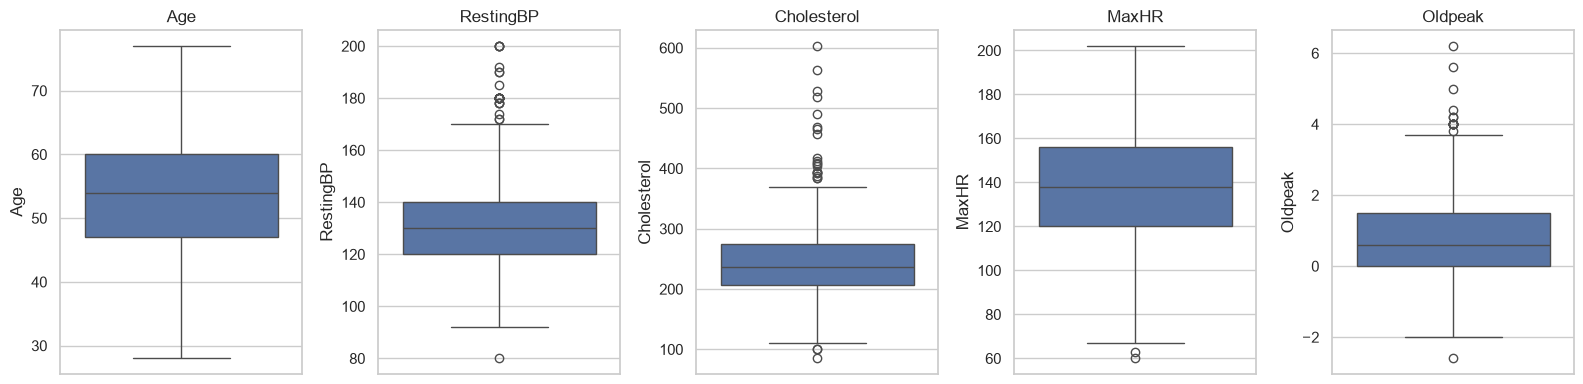

In [12]:
plt.figure(figsize=(16, 4))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df_clean[col])
    plt.title(col)
plt.tight_layout()
plt.show()

**Observation:**

Boxplots show extreme/outlier points above the upper whisker in `RestingBP`, `Cholesterol`, and `Oldpeak`, and a couple of low points in `MaxHR`, while `Age` shows no points outside the whiskers.

### Detect outliers using IQR
Missing values (`NaN`) are ignored automatically.

In [13]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in numeric_cols:
    lower, upper = iqr_bounds(df_clean[col])
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    rows.append({"feature": col, "lower": round(lower, 2), "upper": round(upper, 2), "n_outliers": n_out})

pd.DataFrame(rows)

,feature,lower,upper,n_outliers
0,Age,27.50,79.50,0
1,RestingBP,90.00,170.00,27
2,Cholesterol,105.62,376.62,23
3,MaxHR,66.00,210.00,2
4,Oldpeak,-2.25,3.75,16


**Observation:**

IQR bounds flag **0** outliers in `Age`, **27** in `RestingBP` (`< 90.00` or `> 170.00`), **23** in `Cholesterol` (`> 376.62`), **2** in `MaxHR` (`< 66.00`), and **16** in `Oldpeak` (`> 3.75`).

#### Important note on removing outliers
In medical data, an extreme value can be a **real and clinically important patient** (for example very high blood pressure), not an error.
Before removing anything ask: *is this a mistake, or a rare but valid case?*
Removing valid rare cases can remove exactly the patients the model should learn to recognise.

So instead of deleting rows, we demonstrate **capping** (percentile method): values below the 1st percentile or above the 99th percentile are replaced by those limits.

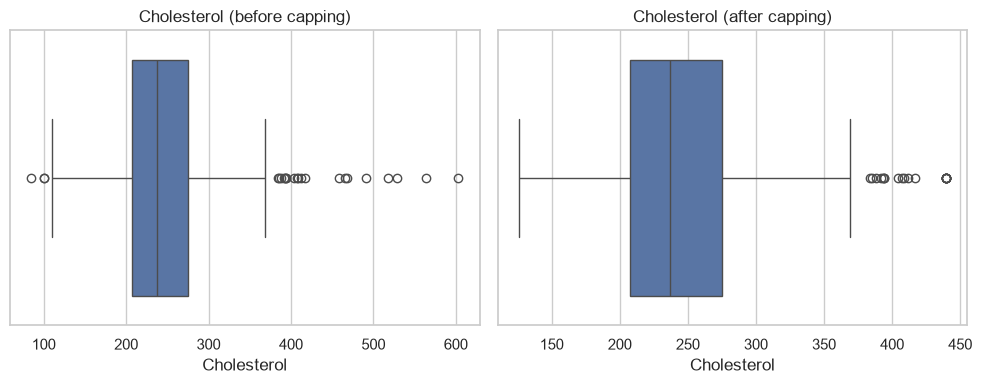

In [14]:
lower_cap = df_clean["Cholesterol"].quantile(0.01)
upper_cap = df_clean["Cholesterol"].quantile(0.99)

chol_capped = df_clean["Cholesterol"].clip(lower_cap, upper_cap)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x=df_clean["Cholesterol"], ax=axes[0]); axes[0].set_title("Cholesterol (before capping)")
sns.boxplot(x=chol_capped, ax=axes[1]);             axes[1].set_title("Cholesterol (after capping)")
plt.tight_layout()
plt.show()

**Observation:**

IQR bounds flag **0** outliers in `Age`, **27** in `RestingBP` (`< 90.00` or `> 170.00`), **23** in `Cholesterol` (`> 376.62`), **2** in `MaxHR` (`< 66.00`), and **16** in `Oldpeak` (`> 3.75`).

**Decision for the project:** keep, cap or remove outliers?

**Keep** outliers rather than deleting rows (and avoid aggressive clipping before modeling), because extreme clinical readings in heart disease data can represent genuinely high-risk patients rather than data-entry errors.

## 6. Data Transformation - Scaling (demonstration)
Features are on very different scales (`Cholesterol` ~ hundreds, `Oldpeak` ~ 0-6). Models that use distances or gradients (KNN, SVM, Logistic Regression, Neural Networks, PCA) are affected; tree-based models (Decision Tree, Random Forest) are not.

For this demonstration we use the median-imputed copy.

In [15]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

demo = df_median[numeric_cols].copy()
demo.describe().loc[["mean", "std", "min", "max"]].round(2)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
mean,53.51,132.54,243.2,136.81,0.89
std,9.43,17.99,53.4,25.46,1.07
min,28.00,80.00,85.0,60.00,-2.60
max,77.00,200.00,603.0,202.00,6.20


### Min-Max normalization
Rescales each feature to the range 0 to 1: `x' = (x - min) / (max - min)`.

In [16]:
minmax = MinMaxScaler()
demo_minmax = pd.DataFrame(minmax.fit_transform(demo), columns=numeric_cols)
demo_minmax.describe().loc[["mean", "std", "min", "max"]].round(2)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
mean,0.52,0.44,0.31,0.54,0.40
std,0.19,0.15,0.10,0.18,0.12
min,0.00,0.00,0.00,0.00,0.00
max,1.00,1.00,1.00,1.00,1.00


**Observation:**

`MinMaxScaler` rescales every numerical feature into the `[0.00, 1.00]` range (`min = 0.00`, `max = 1.00`), preserving distribution shapes while compressing spreads (`std` between `0.10` and `0.19`).

### Z-score standardization
Mean 0 and standard deviation 1: `z = (x - mean) / std`.

In [17]:
standard = StandardScaler()
demo_standard = pd.DataFrame(standard.fit_transform(demo), columns=numeric_cols)
demo_standard.describe().loc[["mean", "std", "min", "max"]].round(2)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
mean,-0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.71,-2.92,-2.96,-3.02,-3.27
max,2.49,3.75,6.74,2.56,4.98


**Observation:**

`StandardScaler` centers each numerical feature to `mean = 0.00` and scales it to `std = 1.00`, while keeping extreme values visible as larger standardized deviations (e.g., `Cholesterol` max `6.74`, `Oldpeak` max `4.98`).

> **Leakage reminder:** in this notebook `fit_transform` ran on the whole dataset only to show the effect.
> In the real pipeline, the scaler is **fit on the training set** and only **transform** is applied to the test set.

## 7. Check correlation before PCA
PCA is useful when features are strongly correlated (they contain overlapping information).
- Close to **1** or **-1**: strong linear relationship
- Close to **0**: weak or no linear relationship

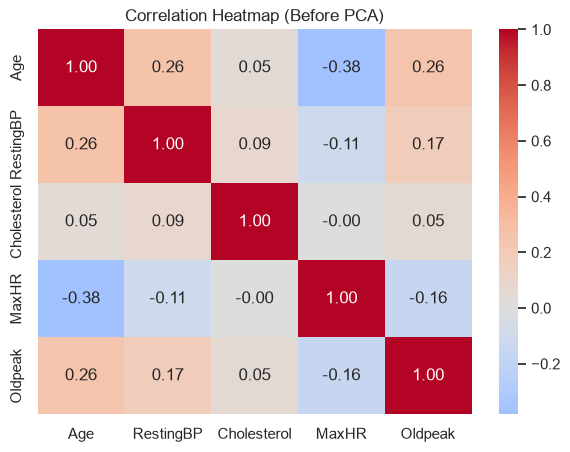

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(demo_standard.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Before PCA)")
plt.show()

**Observation:**

Linear correlations among the standardized numerical features are weak to moderate—the strongest is between `Age` and `MaxHR` (`-0.38`), followed by `Age` with `Oldpeak` (`0.26`) and `RestingBP` (`0.26`), while most other pairs are near zero.

## 8. Data Reduction - PCA (optional demonstration)
If the correlations above are weak, PCA will not reduce the dimensions much. Look at the explained variance to judge.

In [19]:
from sklearn.decomposition import PCA

pca = PCA(n_components=len(numeric_cols))
components = pca.fit_transform(demo_standard)

print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Cumulative:              ", pca.explained_variance_ratio_.cumsum().round(3))

Explained variance ratio: [0.341 0.205 0.174 0.164 0.115]
Cumulative:               [0.341 0.546 0.721 0.885 1.   ]


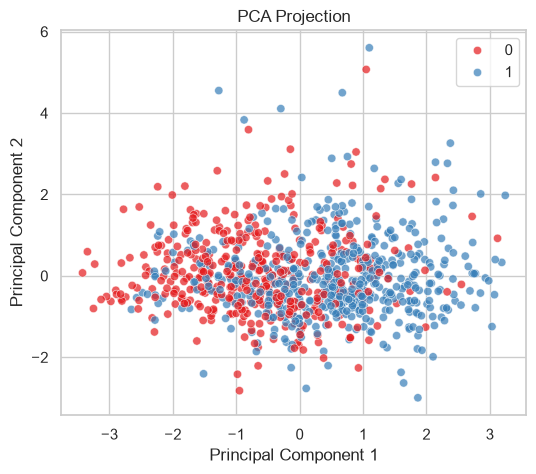

In [20]:
plt.figure(figsize=(6, 5))
sns.scatterplot(x=components[:, 0], y=components[:, 1],
                hue=df_median[target_col].values, palette="Set1", alpha=0.7)
plt.title("PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

**Observation:**

The first two principal components explain only **54.6%** of the variance (`0.341` + `0.205`), and it takes **4 components** to reach `88.5%`, while the 2D projection shows heavy overlap between `HeartDisease = 0` and `1`.

**Decision:** is PCA worth using in the final model? 

**No**, PCA is not worth using in the final model because linear correlations among the 5 numerical features are weak-to-moderate, reducing to 2 components loses nearly half the variance and blends the classes, and keeping original clinical features preserves interpretability.

## 9. Save the cleaned dataset
We save `df_clean`: duplicates removed and hidden zeros converted to `NaN`. Notebook 03 (feature engineering) reads this file.
We deliberately do **not** impute or scale here, so the model notebooks can do those steps correctly after the train/test split.

In [21]:
os.makedirs("../data/processed", exist_ok=True)
df_clean.to_csv("../data/processed/heart_clean.csv", index=False)

print("Saved:", df_clean.shape)
print("Missing values kept as NaN:")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])

Saved: (918, 12)
Missing values kept as NaN:
RestingBP        1
Cholesterol    172
dtype: int64


---
### Task
Repeat the IQR outlier detection for `Age` and `MaxHR` only, print how many outliers each has, and explain whether you would treat them as errors or valid values.

In [23]:
for col in ["Age", "MaxHR"]:
    lower, upper = iqr_bounds(df_clean[col])
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"{col}: {n_out} outliers (bounds: {lower:.2f} to {upper:.2f})")

Age: 0 outliers (bounds: 27.50 to 79.50)
MaxHR: 2 outliers (bounds: 66.00 to 210.00)


`Age` has **0** IQR outliers and `MaxHR` has **2** IQR outliers; I would treat them as **valid clinical values** rather than errors because `Age` (`28–77`) and low peak heart rates (`MaxHR` around `60–65` bpm) are physiologically plausible, especially in older or medicated patients.